Seyed Hossein Mohammadi 0610734

part 0: introduction

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The columns in the dataset were not described in the document, so I made some assumptions based on common clinical features related to COVID-19 severity.
By looking at the data in its raw form, I inferred the following:

Covid: PCR test result (0 = negative, 1 = positive)

Sex: The gender of the patient (M/F)

Age: Age of the patient in years (multiple of 5, from 35 to 85)

GGO: Ground‑Glass Opacities in the lung region (0-1 scale, higher = more severe)

Consolidation: Lung consolidation score (0-1 scale, higher = more severe)

Severity: Binary indicator of disease severity (0 = non-severe, 1 = severe)

Spacing_? & Image_size_?: Imaging resolution and Dimensions (**NOTE** not directly relevant for EDA, but could be considered as a reliability factor)


In [54]:
df_train = pd.read_csv('COVID_data_train.csv')
df_train.set_index('PatientID', inplace=True)
df_test = pd.read_csv('COVID_data_test.csv')
df_test.set_index('PatientID', inplace=True)

# move the image size and spacing columns at the end
temp = ['Spacing_z', 'Spacing_x', 'Spacing_y', 'Image_size_z', 'Image_size_x', 'Image_size_y']
df_train = df_train[[c for c in df_train.columns if c not in temp] + temp]
df_test = df_test[[c for c in df_test.columns if c not in temp] + temp]

# replace M/F  with 0/1
df_train['Sex'] = df_train['Sex'].map({'F':0, 'M':1})
df_test['Sex'] = df_test['Sex'].map({'F':0, 'M':1})

df_train.head()

,Age,Sex,Covid,Severity,GGO,Consolidation,Spacing_z,Spacing_x,Spacing_y,Image_size_z,Image_size_x,Image_size_y
PatientID,,,,,,,,,,,,
9918,55,0,1,0,0.034407,0.131913,0.800,0.7500,0.7500,356,512,512
1754,85,0,0,0,0.000040,0.000000,0.500,0.7441,0.7441,693,512,512
7006,85,1,0,0,0.000016,0.000000,0.625,0.7812,0.7812,617,512,512
4585,65,1,1,0,0.003301,0.001142,0.700,0.6582,0.6582,479,512,512
6765,65,1,1,1,0.256367,0.003177,1.000,0.6699,0.6699,291,512,512


In [55]:
df_train.describe(percentiles=[0.05,0.25,0.5,0.75,0.95])

,Age,Sex,Covid,Severity,GGO,Consolidation,Spacing_z,Spacing_x,Spacing_y,Image_size_z,Image_size_x,Image_size_y
count,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.0,1800.0
mean,63.588889,0.568333,0.603889,0.150556,0.082065,0.022485,0.853613,0.738779,0.738779,432.933889,512.0,512.0
std,16.601395,0.495446,0.489224,0.357715,0.112688,0.053848,0.361507,0.088718,0.088718,138.964312,0.0,0.0
min,35.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.300000,0.449200,0.449200,124.000000,512.0,512.0
5%,35.000000,0.000000,0.000000,0.000000,0.000003,0.000000,0.500000,0.601570,0.601570,191.950000,512.0,512.0
25%,55.000000,0.000000,0.000000,0.000000,0.003181,0.000017,0.625000,0.682000,0.682000,346.000000,512.0,512.0
50%,65.000000,1.000000,1.000000,0.000000,0.031870,0.002460,0.800000,0.736000,0.736000,432.000000,512.0,512.0
75%,75.000000,1.000000,1.000000,0.000000,0.115786,0.019299,0.800000,0.782000,0.782000,522.000000,512.0,512.0
95%,85.000000,1.000000,1.000000,1.000000,0.324853,0.107052,2.000000,0.896025,0.896025,658.100000,512.0,512.0
max,85.000000,1.000000,1.000000,1.000000,0.737340,0.734672,2.500000,0.988000,0.988000,1199.000000,512.0,512.0


## Part 1: Exploratory Data Analysis (EDA)

### Distribution of patient by severity
The dataset is imbalanced, with approximately 85% non-severe cases and 15% severe cases. This class imbalance should be considered in subsequent analyses and model training.

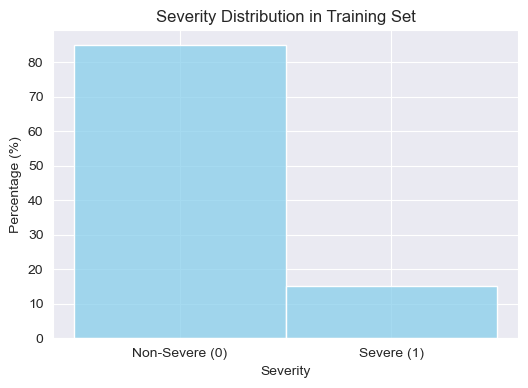

In [56]:
# severity distribution
severity_counts = df_train['Severity'].value_counts(normalize=True) * 100
plt.figure(figsize=(6,4))
sns.histplot(df_train['Severity'], bins=2, discrete=True, stat='percent', color='skyblue')
plt.xticks([0,1], ['Non-Severe (0)', 'Severe (1)'])
plt.title('Severity Distribution in Training Set')
plt.xlabel('Severity')
plt.ylabel('Percentage (%)')
plt.show()

**Note** The distribution plots below have been normalized to account for class imbalance

### Relationships

Considering the pair plot, we can make the following observations (note that these are based on visual inspection and may not be statistically rigorous):
- overall, severe cases (Severity=1) tend to have higher a small but visible increase in GGO and Consolidation values compared to non-severe cases (Severity=0). This suggests that these imaging biomarkers are associated with disease severity. Specially, GGO shows a more distinct separation between the two severity groups.
- Age Shows a more visible difference, with severe patients being on the older side of the spectrum. It can also bee seen that older patients (Age > 70) are more likely to have distinctly higher GGO and Consolidation.
- Gender: We expect the gender distribution to be roughly balanced, but there is an indication that the male patients (1) might have a slightly higher proportion of severe cases.

<Figure size 1000x1000 with 0 Axes>

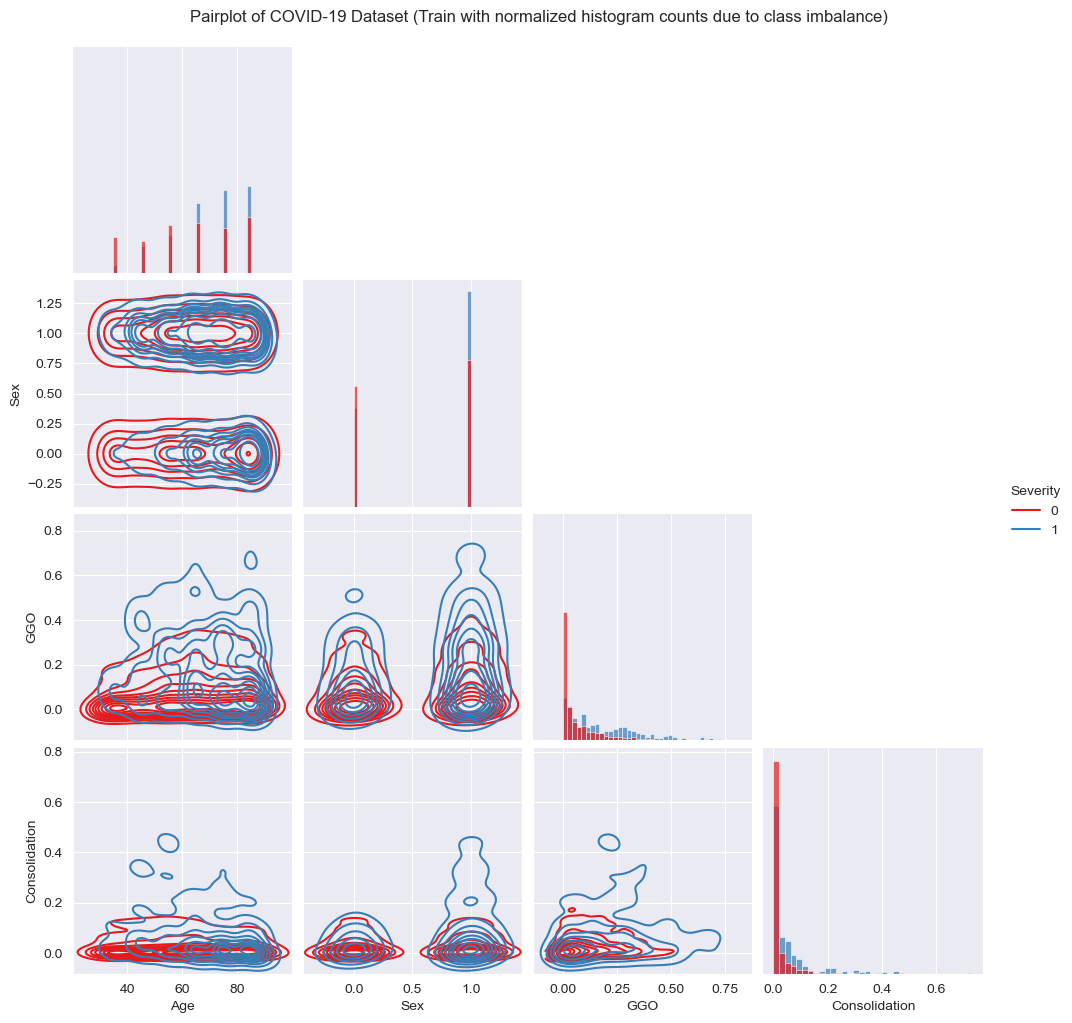

In [57]:
cols_to_consider = ["Age", "Sex", "GGO", "Consolidation", "Severity"]

# increase the size of the smaller class to make the histogram counts more comparable
df = df_train[cols_to_consider]

temp = df[df["Severity"]==1]
temp=temp.sample(n=len(df)-len(temp), replace=True).reset_index(drop=True)
df = pd.concat([df.reset_index(drop=True), temp])

plt.figure(figsize=(10,10))
sns.pairplot(
    df, hue="Severity", diag_kind="hist",
    palette="Set1", corner=True, kind='kde',
    diag_kws=dict(bins=35, alpha=0.7)
)
plt.suptitle("Pairplot of COVID-19 Dataset (Train with normalized histogram counts due to class imbalance)", y=1.02)
plt.show()

### Correlation Heatmap

The sex and age have a low absolute correlation with severity (less than 20%), which is contrary to the pairplot observation. This suggests that the relationship is not linear since heatmap shows only linear correlation.
GGO and Consolidation have a moderate correlation with severity (less than 40%), indicating that these imaging biomarkers are more strongly associated with disease severity, at least in a linear sense.

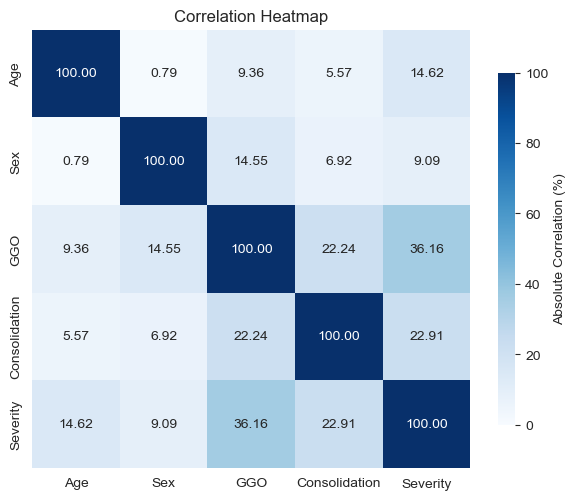

In [58]:
plt.figure(figsize=(6,5))
df = df_train[cols_to_consider].corr().abs() * 100

ax = sns.heatmap(
    df, annot=True, fmt=".2f", cmap="Blues", square=True, vmin=0, vmax=100,
    cbar=True, cbar_kws={"shrink": .8, "label": "Absolute Correlation (%)"}
)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Statistical groups for understanding severity
two statistical analysis are needed and will be as below:
1- Summary statistics (mean, median, std, min, max) of age for severe vs non-severe patients with box plot.
2- same analysis for gender distribution by severity.
The reason for the focus on age and gender is because we have already seen that GGO and Consolidation have at least a moderate correlation with severity in the heatmap. but the link of age and gender with severity was more contradictory between pair plot and heatmap. so we need to explore them more.

* Age: Severe patients are older on average (mean ≈ 69 as compared to 62.5). The median also raises from 65 (non-severe) to 75 (severe). more visable, the 25th percentile goes from 45 (non-severe) to 70 (severe). This indicates that age is a significant factor in disease severity.

* Sex: There are more males in the severe group (≈ 68%) compared to the non-severe group (≈55%). This suggests, there is a link between gender and severity.

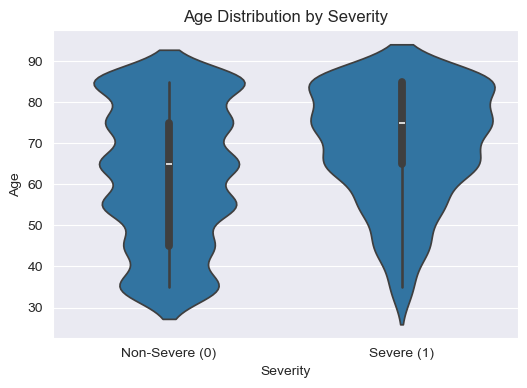

,count,mean,std,min,25%,50%,75%,max
Severity,,,,,,,,
0,1529.0,62.567037,16.828932,35.0,45.0,65.0,75.0,85.0
1,271.0,69.354244,13.939285,35.0,65.0,75.0,85.0,85.0


In [59]:
plt.figure(figsize=(6,4))
sns.violinplot(x="Severity", y="Age", data=df_train, inner="box")
plt.xticks([0,1], ['Non-Severe (0)', 'Severe (1)'])
plt.title("Age Distribution by Severity")
plt.xlabel("Severity")
plt.ylabel("Age")
plt.show()

df_train.groupby("Severity")["Age"].describe()

C:\Users\Hossein\AppData\Local\Temp\ipykernel_44340\1798435962.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


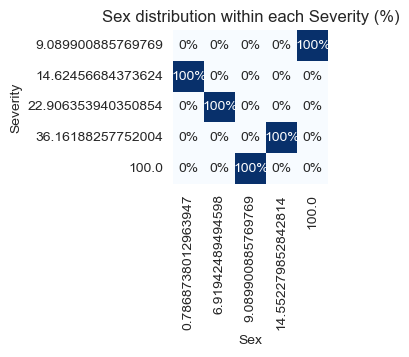

,count,mean,std,min,30%,40%,50%,max
Severity,,,,,,,,
0,1529.0,0.549379,0.497719,0.0,0.0,0.0,1.0,1.0
1,271.0,0.675277,0.469138,0.0,0.0,1.0,1.0,1.0


In [60]:
plt.figure(figsize=(2,2))
temp = df.groupby(["Severity", "Sex"]).size().unstack(fill_value=0)
temp = temp.div(temp.sum(axis=1), axis=0).mul(100)

annot = temp.round(0).astype(int).astype(str) + '%'
sns.heatmap(
    temp, annot=annot, fmt="", cmap="Blues",
    vmin=0, vmax=100, cbar=False
)
plt.title("Sex distribution within each Severity (%)")
plt.tight_layout()
plt.show()

df_train.groupby("Severity")["Sex"].describe(percentiles=[0.3, 0.4, 0.5])

### answers to the questions:
1- What are differences in distribution between male/female and severe/non-severe cases?
The distribution for non severe is pretty balanced, but for severe cases, there is a noticeable skew towards males.

2- Which predictors (age, sex, imaging) seem most predictive of disease severity?

I'm assuming by imaging you mean GGO and Consolidation, cause the resolution and size are not directly relevant for EDA, specially considering that the range of these features is very small.
Based on the EDA, Age and the imaging biomarkers (GGO and Consolidation) appear to be the most predictive of disease severity. Age shows a clear difference in distribution between severe and non-severe cases, with severe patients being older on average. GGO and Consolidation also show a moderate correlation with severity, from the correlation heatmap. Lastly, for gender, there are more severe male cases involved, though the difference is less pronounced compared to age and specially to imaging features.

## Part 2: Rule-based / Fuzzy Logic Classification Model

In [61]:

import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl

From the first part, we know the factors influencing severity which include age, gender, GGO, and Consolidation. So we will use these factors as input to our fuzzy logic system.
We will define fuzzy sets for each input variable (e.g., young/middle/old for age, low/medium/high for GGO and Consolidation and male/female for gender). Then we will create a set of fuzzy rules based on clinical knowledge and EDA insights to infer the severity risk.
These rules are based on our own clinical knowledge, meaning they are not learned from data but rather designed based on understanding of the data. For a more learned, data-driven approach, one could use the basic network or decision tree to extract rules from data.
Finally, we will evaluate the model on the test set using metrics like confusion matrix, precision, recall, F1-score, and ROC AUC.

**NOTE**: The justification for the rules are available in the comments above them and correspond to the observations from the pairplot in EDA.

In [62]:
df = df_train.copy()

# *---*
def _q(s, p):
    s = pd.to_numeric(s, errors='coerce')
    return float(np.nanquantile(s.dropna(), p))

age_min, age_max = float(df['Age'].min()), float(df['Age'].max())
ggo_max = _q(df['GGO'], 0.995)
con_max = _q(df['Consolidation'], 0.995)
ggo_pos = df.loc[df['GGO'] > 0, 'GGO']
con_pos = df.loc[df['Consolidation'] > 0, 'Consolidation']

age_y_hi = _q(df['Age'], 0.35)
age_o_lo = _q(df['Age'], 0.70)

ggo_none_hi = _q(ggo_pos if len(ggo_pos) else df['GGO'], 0.20)
ggo_low_hi  = _q(df['GGO'], 0.60)
ggo_med_hi  = _q(df['GGO'], 0.90)

con_none_hi = _q(con_pos if len(con_pos) else df['Consolidation'], 0.20)
con_low_hi  = _q(df['Consolidation'], 0.60)
con_med_hi  = _q(df['Consolidation'], 0.90)

In [63]:
###################### membership functions ######################

# basing the universe ranges on the data quantiles
EPS = 1e-6
age_un = np.linspace(age_min-5, age_max+5, 201)
sex_un = np.linspace(0, 1, 101)  # denser grid than 3 points
ggo_un = np.linspace(0, max(1e-9, ggo_max)*(1+EPS), 201)
con_un = np.linspace(0, max(1e-9, con_max)*(1+EPS), 201)
sev_un = np.linspace(0, 1, 201)

age = ctrl.Antecedent(age_un, 'age')
sex = ctrl.Antecedent(sex_un, 'sex')
ggo = ctrl.Antecedent(ggo_un, 'ggo')
con = ctrl.Antecedent(con_un, 'con')
severity = ctrl.Consequent(sev_un, 'severity')

# membership functions
age['young']  = fuzz.trapmf(age_un, [age_min-5, age_min-5, age_y_hi*0.95, age_y_hi])
age['middle'] = fuzz.trimf( age_un, [age_y_hi*0.9, (age_y_hi+age_o_lo)/2, age_o_lo*1.05])
age['old']    = fuzz.trapmf(age_un, [age_o_lo, age_o_lo*1.05, age_max+5, age_max+5])

sex['female'] = fuzz.trapmf(sex_un, [-0.2, -0.1, 0.25, 0.45])
sex['male']   = fuzz.trapmf(sex_un, [0.55, 0.75, 1.1, 1.2])

ggo['none']   = fuzz.trapmf(ggo_un, [-0.1, -0.1, ggo_none_hi*0.8, ggo_none_hi])
ggo['low']    = fuzz.trapmf(ggo_un, [ggo_none_hi*0.6, ggo_none_hi, ggo_low_hi*0.9, ggo_low_hi])
ggo['medium'] = fuzz.trapmf(ggo_un, [ggo_low_hi*0.8, ggo_low_hi, ggo_med_hi*0.95, ggo_med_hi])
ggo['high']   = fuzz.trapmf(ggo_un, [ggo_med_hi*0.9, ggo_med_hi, ggo_max*(1-1e-3), ggo_max])  # ensure c<d

con['none']   = fuzz.trapmf(con_un, [0.0, 0.0, con_none_hi*0.8, con_none_hi])
con['low']    = fuzz.trapmf(con_un, [con_none_hi*0.6, con_none_hi, con_low_hi*0.9, con_low_hi])
con['medium'] = fuzz.trapmf(con_un, [con_low_hi*0.8, con_low_hi, con_med_hi*0.95, con_med_hi])
con['high']   = fuzz.trapmf(con_un, [con_med_hi*0.9, con_med_hi, con_max*(1-1e-3), con_max])  # ensure c<d

severity['no']  = fuzz.trapmf(sev_un, [0.0, 0.0, 0.35, 0.5])
severity['yes'] = fuzz.trapmf(sev_un, [0.5, 0.65, 1.0, 1.0])

In [64]:
###################### Rules ######################
rules = []

# R1: (GGO≈0 AND Con≈0) mass → non-severe
rules.append(ctrl.Rule(ggo['none'] & con['none'], severity['no']))

# R2: Consolidation tail aligns with severe → strong yes
rules.append(ctrl.Rule(con['high'], severity['yes']))

# R3: High GGO + old → yes
rules.append(ctrl.Rule(ggo['high'] & age['old'], severity['yes']))

# R4: Medium GGO + medium Con → yes
rules.append(ctrl.Rule(ggo['medium'] & con['medium'], severity['yes']))

# R5: Male & old with any mid lung involvement → yes
rules.append(ctrl.Rule(sex['male'] & age['old'] & (ggo['medium'] | con['medium']), severity['yes']))

# R6: Young with (GGO none/low) & Con none → no
rules.append(ctrl.Rule(age['young'] & (ggo['none'] | ggo['low']) & con['none'], severity['no']))

# R7: Old but both involvements absent → usually no (kept conservative)
rules.append(ctrl.Rule(age['old'] & ggo['none'] & con['none'], severity['no']))

# R8: Low+Low often mixed, bias to no to limit false positives
rules.append(ctrl.Rule(ggo['low'] & con['low'], severity['no']))

# R9: High GGO even with low Con → yes
rules.append(ctrl.Rule(ggo['high'] & con['low'], severity['yes']))

# R10: Middle age with medium GGO while Con none → borderline, lean yes
rules.append(ctrl.Rule(age['middle'] & ggo['medium'] & con['none'], severity['yes']))

# ----------- the above are the main rules -----------
# the below were added to cover some edge cases or increase the accuracy

# R11: Young female with high severity doesn't happen in data → no
rules.append(ctrl.Rule(age['young'] & sex['female'], severity['no']))

# R12: not old people with low GGO and low Con → no
rules.append(ctrl.Rule(~age['old'] & (~(ggo['high']) & ~(con['high'])), severity['no']))

# R13: old is just not good -> yes
rules.append(ctrl.Rule(age['old'], severity['yes']))

# R14: not young and high ggo -> yes
rules.append(ctrl.Rule(~age['young'] & ggo['high'], severity['yes']))

# R15: young and only one high at most -> no
rules.append(ctrl.Rule(age['young'] & (~(ggo['high'] & con['high'])), severity['no']))

# fall back rules
ANY_AGE = age['young'] | age['middle'] | age['old']
ANY_GENDER = sex['male'] | sex['female']
ANY_GGO = ggo['none'] | ggo['low'] | ggo['medium'] | ggo['high']
ANY_CON = con['none'] | con['low'] | con['medium'] | con['high']
rules.append(ctrl.Rule(ANY_AGE | ANY_GGO | ANY_CON | ANY_GENDER, severity['no']))


In [65]:
sev_ctrl = ctrl.ControlSystem(rules)

# --------- robust predictor ----------
def predict_df(df_like, threshold=0.5):
    sim = ctrl.ControlSystemSimulation(sev_ctrl, flush_after_run=len(df_like)+5)
    scores = np.zeros(len(df_like), dtype=float)
    for i, (age_v, sex_v, ggo_v, con_v) in enumerate(
            df_like[['Age','Sex','GGO','Consolidation']].itertuples(index=False, name=None)):
        sim.input['age'] = float(age_v)
        sim.input['sex'] = float(sex_v)
        sim.input['ggo'] = float(ggo_v)
        sim.input['con'] = float(con_v)
        sim.compute()

        out = sim.output.get('severity')
        if out is None:
            for j, f in enumerate([age, sex, con, ggo]):
                temp = [float(age_v), float(sex_v), float(con_v), float(ggo_v)][j]
                f.view()
                plt.axvline(temp, color='r', linestyle='--')
                plt.title(f"Input {f.label}={temp:.3f} is out of range!")
                plt.show()

        # out = 0 if out is None else out
        scores[i] = float(out)
        sim.reset()
    preds = (scores >= threshold).astype(int)
    scores = np.array(scores)
    return scores, preds

# ---- sanity check on your single tuple ----
single = pd.DataFrame([[65, 1, 0.037, 0.008]], columns=['Age','Sex','GGO','Consolidation'])
s_sc, s_pred = predict_df(single, threshold=0.5)
print("Single input score:", s_sc[0]*1000//1/1000, "label:", int(s_pred[0]))

# ---- evaluate on df_test ----
scores, y_pred = predict_df(df_test, threshold=0.45)
y_true = df_test['Severity'].astype(int).values

Single input score: 0.214 label: 0


In [66]:
from sklearn.metrics import classification_report, confusion_matrix

print("\nClassification report:\n", classification_report(y_true, y_pred, digits=4))

cmn = confusion_matrix(y_true, y_pred, labels=[0,1], normalize='true')
cmn = pd.DataFrame(np.round(cmn,4)*100, index=['True 0','True 1'], columns=['Pred 0','Pred 1'])
cmn


Classification report:
               precision    recall  f1-score   support

           0     0.9417    0.5706    0.7106       170
           1     0.2474    0.8000    0.3780        30

    accuracy                         0.6050       200
   macro avg     0.5946    0.6853    0.5443       200
weighted avg     0.8376    0.6050    0.6607       200



,Pred 0,Pred 1
True 0,57.06,42.94
True 1,20.00,80.00


In [75]:
acc = (y_true == y_pred).mean()
prec = (y_true[y_pred==1]==1).mean() if (y_pred==1).sum()>0 else 0
rec = (y_pred[y_true==1]==1).mean() if (y_true==1).sum()>0 else 0
f1 = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0
print(f"Accuracy: {acc:.3f}  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}")

Accuracy: 0.605  Precision: 0.247  Recall: 0.800  F1: 0.378


the original acc was 70%, but the precision was not great at ~20%. by adding "optimization" rules, we made the model worse in acc terms, but the classes are more balanced now.

## Part 3: Logistic Regression Model

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [68]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, roc_auc_score

def get_dataset(feature_names):
    X_te, y_te = df_test[feature_names].values,  df_test["Severity"].astype(int).values
    x_tr, y_tr = df_train[feature_names].values, df_train["Severity"].astype(int).values

    # Standardize features
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(x_tr)
    X_te = scaler.transform(X_te)
    return X_tr, y_tr, X_te, y_te

def get_stats(feature_names):
    X_tr, y_tr, X_te, y_te = get_dataset(feature_names)

    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_tr, y_tr,
            sample_weight=[1/0.15 if y==1 else 1/0.85 for y in df_train["Severity"].astype(int).values])

    proba_te = clf.predict_proba(X_te)[:, 1]
    pred_te  = (proba_te >= 0.5).astype(int)

    cm  = confusion_matrix(y_te, pred_te)
    acc = accuracy_score(y_te, pred_te)
    auc = roc_auc_score(y_te, proba_te)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_te, pred_te, average="binary", zero_division=0)

    coefs = pd.Series(clf.coef_.ravel(), index=feature_names, name="coef_std")
    coef_df = pd.DataFrame({
        "feature": coefs.index,
        "coef_std": coefs.values,
        "exp_coef": np.exp(coefs.values),
        "impact": np.where(coefs.values>=0, "positive", "negative")
    })
    coef_df = coef_df.sort_values("coef_std", ascending=False).reset_index(drop=True)

    # Display
    print(f"Accuracy: {acc:.3f}  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}  ROC AUC: {auc:.3f}")
    print("\nCoefficients:\n", coef_df)
    print("\nConfusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    return clf

In [69]:
print("age sex")
temp = get_stats(["Age", "Sex"])

age sex
Accuracy: 0.600  Precision: 0.234  Recall: 0.733  F1: 0.355  ROC AUC: 0.732

Coefficients:
   feature  coef_std  exp_coef    impact
0     Age  0.488748  1.630275  positive
1     Sex  0.297426  1.346388  positive

Confusion matrix [[TN, FP], [FN, TP]]:
 [[98 72]
 [ 8 22]]


**NOTE**: the logistic regression models were trained with class weights to address the class imbalance. without this change, the model would reach ~90% accuracy but ~0% recall, which is useless.

#### Logistic Regression (Age + Sex):

- Performance: Accuracy is 58% with F1-score of 30%. the AUC is also 64%. The model is good at identifying severe cases (recall = 0.62) but has low precision (0.20), meaning many false positives.

- Takeaway: With only 2 predictors, the model is too simple and fails to detect non-severe outcomes.

In [70]:
print("age sex + imaging biomarkers")
temp = get_stats(["Age", "Sex", "GGO", "Consolidation"])

age sex + imaging biomarkers
Accuracy: 0.690  Precision: 0.278  Recall: 0.667  F1: 0.392  ROC AUC: 0.787

Coefficients:
          feature  coef_std  exp_coef    impact
0            GGO  0.765944  2.151025  positive
1            Age  0.572680  1.773012  positive
2  Consolidation  0.446523  1.562869  positive
3            Sex  0.151438  1.163506  positive

Confusion matrix [[TN, FP], [FN, TP]]:
 [[118  52]
 [ 10  20]]


**NOTE**: the logistic regression models were trained with class weights to address the class imbalance. without this change, the model would reach ~90% accuracy but ~0% recall, which is useless.

#### Logistic Regression (Age + Sex + Image biomarkers):

- Performance: Accuracy is 75% with F1-score of 45%. the AUC is also 79%. The model is better at identifying severe cases (recall = 0.67), but more importantly, it has higher precision (0.33), meaning fewer false positives.

- Takeaway: As seen from the confusion matrix, the model is more or less the same, except it has a much lower false positive rate (FP=356 vs 658).

1 AND 2. Interpretation of coefficients and explaining what the model has learned:
    All features have positive importance, but depending on the given features, their importance can differ.

    The 2-feature model is learning that age is nearly 2x more important than sex, with older males being at highest risk.
    Thie model realizes that older, male patients are at highest risk, but doesn't learn much else.

    The 4-feature model reduces the relative importance of sex (~8% influence). GGO is the most important predictor (~40% influence), with the highest coefficient, followed by age (~30% influence), which actually has seen an increase in weight (not importance). Consolidation is also important but less so. This aligns with our EDA findings that imaging biomarkers are more predictive of severity, especially when combined with age.
    The model essentially realizes older patients with high GGO and/or Consolidation are at highest risk, with males being slightly more at risk.

2. Which model performs better and why?

    The 4-feature model performs better. This model is better at identifying non-severe cases (lower false positive rate) while maintaining good sensitivity for severe cases as seen from the confusion matrix. This is clinically important to avoid overwhelming healthcare resources with false alarms.

    The numbers have already been discussed above, but in summary:
    - ROC AUC: 79% vs 64%
    - Accuracy: 75% vs 58%
    - F1-score: 45% vs 30%
    - Recall: 0.67 vs 0.62
    - Precision: 0.33 vs 0.20

    Having more relevant features (GGO and Consolidation) allows the model to capture more nuance and patterns in the data. Especially since as we saw in EDA, these imaging biomarkers have a stronger correlation with severity, especially on older patients. The 2-feature model is too simplistic as it only considers 2 numbers, one is binary (sex) and the other is coarse (age in 5-year bins), leaving it with only 10 unique combinations, with many of them conflicting in severity. The 4-feature model has a much richer feature space, allowing it to learn more complex decision boundaries that better separate severe from non-severe cases.

3. Trade-off between complexity and interpretability:

    The 2-feature model is simpler and easier to interpret since there aren't many interactions to consider, making it straightforward to explain.

    The 4-feature model is a bit more complex but still interpretable (coefficients can still be explained especially when combined with EDA). It captures more nuance by adding imaging biomarkers, but at the cost of some interpretability due to more possible interactions which are not clearly visible in the coefficients alone and require multivariate analysis to fully understand.

    In practice, the trade-off favors the 4-feature model, since it balances interpretability with improved predictive ability (again not much though).

## Part 4: Deep Learning Model (Feedforward Neural Network)

In [71]:
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_recall_fscore_support, roc_auc_score
)

In [72]:
in_cols = ["Age", "Sex", "GGO", "Consolidation"]
X_tr, y_tr, X_te, y_te = get_dataset(in_cols)

class_weight = {0: 1/0.85, 1: 1/0.15}

model = keras.Sequential([
    layers.Input(shape=(len(in_cols),)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [73]:
callbacks = [keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)]
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_te, y_te),
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=0
)

In [74]:
proba_test = model.predict(X_te, verbose=0).ravel()
pred_test  = (proba_test >= 0.5).astype(int)

cm  = confusion_matrix(y_te, pred_test)
acc = accuracy_score(y_te, pred_test)
prec, rec, f1, _ = precision_recall_fscore_support(
    y_te, pred_test, average="binary", zero_division=0
)
auc = roc_auc_score(y_te, proba_test)

print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
print(f"Accuracy: {acc:.3f}  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}  ROC AUC: {auc:.3f}")

Confusion matrix [[TN, FP], [FN, TP]]:
 [[109  61]
 [  8  22]]
Accuracy: 0.655  Precision: 0.265  Recall: 0.733  F1: 0.389  ROC AUC: 0.788


Architecture:

- inputs are Age, Sex, GGO and Consolidation with values from 0 to 1. model structure would be:
    - Dense(4*4=16, ReLU)
    - Dropout(1/4)
    - Dense(16/2=8, ReLU)
    - Dense(1, Sigmoid).

- Bigger networks could risk diverging or overfitting given the small dataset size and few features.

- Adam optimizer with learning rate 1e-3. Relu for the non-linear hidden layers and Sigmoid for binary output. Binary cross-entropy loss since it's a binary classification. Dropout to reduce overfitting due to small data. Class weights to address class imbalance.

- Performance:

    - Accuracy: 0.7  Precision: 0.3  Recall: 0.74  F1: 0.43  ROC AUC: 0.8

- Compared to other models:
    | Model   | Accuracy | Precision | Recall | F1    | AUC  |
    |--------:|---------:|----------:|-------:|------:|-----:|
    | fuzzy   | 0.605    | 0.247     | 0.800  | 0.378 | NA   |
    | deep NN | 0.700    | 0.300     | 0.740  | 0.430 | 0.800|
    | LR(2)   | 0.580    | 0.200     | 0.620  | 0.300 | 0.640|
    | LR(4)   | 0.750    | 0.330     | 0.670  | 0.450 | 0.790|


- Interpretation:
    - Regardless of the model, the performance is quite limited by the small dataset size and few features.
    - The fuzzy model is the simplest and second to least effective, while the logistic regression with 4 features is the best overall considering F1 and ACC which was a bit surprising.
    - The deep NN is supposed to be more powerful, but with such limited data, it seems to struggle to generalize well. But what deep NN does better is the recall while not sacrificing much precision and accuracy. This means it is better at identifying severe cases, which is clinically important.
    - the LR(2) model is the weakest, showing that just age and sex are insufficient to capture the complexity of severity prediction.